### Features Engineering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import os, sys, gc, time, warnings, pickle, psutil, random
from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
from lightgbm import early_stopping, log_evaluation
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split, GridSearchCV
import seaborn as sns
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import pandas as pd

# Giả sử bạn đã đọc 3 file csv thành 3 dataframe
texas = pd.read_csv('texas.csv')
cali = pd.read_csv('california.csv')
wicosin = pd.read_csv('wicosin.csv')


# Tính trung bình độ ẩm theo ngày cho từng bang
texas = texas.groupby('day')['avg_rh'].mean().reset_index()
cali = cali.groupby('day')['avg_rh'].mean().reset_index()
wicosin = wicosin.groupby('day')['avg_rh'].mean().reset_index()

# Thêm cột state_id cho từng dataframe
texas['state_id'] = '1'
cali['state_id'] = '2'
wicosin['state_id'] = '3'

# Đổi tên cột avg_rh thành huminity
texas = texas.rename(columns={'avg_rh': 'huminity', 'day':'date'})
cali = cali.rename(columns={'avg_rh': 'huminity', 'day':'date'})
wicosin = wicosin.rename(columns={'avg_rh': 'huminity','day':'date'})


# Gộp 3 dataframe lại với nhau, chọn đúng các cột cần thiết
combined_df = pd.concat([texas[['date', 'state_id', 'huminity']],
                         cali[['date', 'state_id', 'huminity']],
                         wicosin[['date', 'state_id', 'huminity']]],
                        ignore_index=True)

print(combined_df)

combined_df['date'] = pd.to_datetime(combined_df['date'])
combined_df['state_id'] = combined_df['state_id'].astype('int')
combined_df['date']
merged_df = pd.merge(df, combined_df, on=['state_id', 'date'], how='left')

            date state_id   huminity
0     2013-11-22        1  82.202739
1     2013-11-23        1  81.531886
2     2013-11-24        1  77.794254
3     2013-11-25        1  85.823125
4     2013-11-26        1  72.096567
...          ...      ...        ...
2818  2016-06-15        3  81.904496
2819  2016-06-16        3  76.697218
2820  2016-06-17        3  71.289691
2821  2016-06-18        3  67.837256
2822  2016-06-19        3  60.353264

[2823 rows x 3 columns]


0      2013-11-22
1      2013-11-23
2      2013-11-24
3      2013-11-25
4      2013-11-26
          ...    
2818   2016-06-15
2819   2016-06-16
2820   2016-06-17
2821   2016-06-18
2822   2016-06-19
Name: date, Length: 2823, dtype: datetime64[ns]

In [ ]:
df = df

In [2]:
df = pd.read_parquet('../data/train_val.parquet')
df.head()

,id,item_id,store_id,state_id,dept_id,cat_id,d,demand,lag_t7,rolling_mean_lag7_w7,...,event_name_2,snap_CA,snap_TX,snap_WI,sell_price,disaster_type,disaster_severity_flag,flag_ufc,humidity,gold_price
0,HOBBIES_1_001_CA_1,1438,1,1,4,2,1029,0.0,0.0,1.000000,...,1,0,0,0,8.26,None,0,0,64.636551,1244.099976
1,HOBBIES_1_002_CA_1,1439,1,1,4,2,1029,0.0,1.0,0.142857,...,1,0,0,0,3.97,None,0,0,64.636551,1244.099976
2,HOBBIES_1_003_CA_1,1440,1,1,4,2,1029,0.0,0.0,0.000000,...,1,0,0,0,NaN,None,0,0,64.636551,1244.099976
3,HOBBIES_1_004_CA_1,1441,1,1,4,2,1029,3.0,0.0,1.142857,...,1,0,0,0,4.64,None,0,0,64.636551,1244.099976
4,HOBBIES_1_005_CA_1,1442,1,1,4,2,1029,1.0,1.0,0.428571,...,1,0,0,0,3.08,None,0,0,64.636551,1244.099976


In [3]:
df['date']

0          2013-11-22
1          2013-11-22
2          2013-11-22
3          2013-11-22
4          2013-11-22
              ...    
28691085   2016-06-19
28691086   2016-06-19
28691087   2016-06-19
28691088   2016-06-19
28691089   2016-06-19
Name: date, Length: 28691090, dtype: datetime64[ns]

In [4]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

df = downcast(df)

In [5]:
print(len(df.columns))
print(df.columns)

29
Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc', 'humidity', 'gold_price'],
      dtype='object')


In [6]:
df = df.drop(['date','disaster_type','humidity'],axis=1)

In [7]:
print(len(df.columns))
print(df.columns)

26
Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'wday',
       'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA', 'snap_TX',
       'snap_WI', 'sell_price', 'disaster_severity_flag', 'flag_ufc',
       'gold_price'],
      dtype='object')


In [8]:
len(df['id'])

28691090

In [11]:
df

,id,item_id,store_id,state_id,dept_id,cat_id,d,demand,lag_t7,rolling_mean_lag7_w7,...,year,event_name_1,event_name_2,snap_CA,snap_TX,snap_WI,sell_price,disaster_severity_flag,flag_ufc,gold_price
0,HOBBIES_1_001_CA_1,1438,1,1,4,2,1029,0.0,0.0,1.000000,...,2013,1,1,0,0,0,8.26,0,0,1244.099976
1,HOBBIES_1_002_CA_1,1439,1,1,4,2,1029,0.0,1.0,0.142857,...,2013,1,1,0,0,0,3.97,0,0,1244.099976
2,HOBBIES_1_003_CA_1,1440,1,1,4,2,1029,0.0,0.0,0.000000,...,2013,1,1,0,0,0,NaN,0,0,1244.099976
3,HOBBIES_1_004_CA_1,1441,1,1,4,2,1029,3.0,0.0,1.142857,...,2013,1,1,0,0,0,4.64,0,0,1244.099976
4,HOBBIES_1_005_CA_1,1442,1,1,4,2,1029,1.0,1.0,0.428571,...,2013,1,1,0,0,0,3.08,0,0,1244.099976
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19995,FOODS_1_091_TX_3,90,7,2,1,1,1029,0.0,0.0,0.000000,...,2013,1,1,0,0,0,2.48,0,0,1244.099976
19996,FOODS_1_092_TX_3,91,7,2,1,1,1029,0.0,2.0,2.000000,...,2013,1,1,0,0,0,1.78,0,0,1244.099976
19997,FOODS_1_093_TX_3,92,7,2,1,1,1029,0.0,0.0,0.000000,...,2013,1,1,0,0,0,5.93,0,0,1244.099976
19998,FOODS_1_094_TX_3,93,7,2,1,1,1029,0.0,0.0,0.000000,...,2013,1,1,0,0,0,3.28,0,0,1244.099976


Alpha tối ưu: 0.06951927961775606
R² score trên tập train: 0.4878
R² score trên tập test: 0.6316

Các feature được chọn bởi Lasso:
                   Feature  Coefficient  Abs_Coefficient
6                   lag_t7     0.966946         0.966946
7     rolling_mean_lag7_w7     0.926889         0.926889
10   rolling_mean_lag28_w7     0.396669         0.396669
11  rolling_mean_lag28_w28     0.138347         0.138347


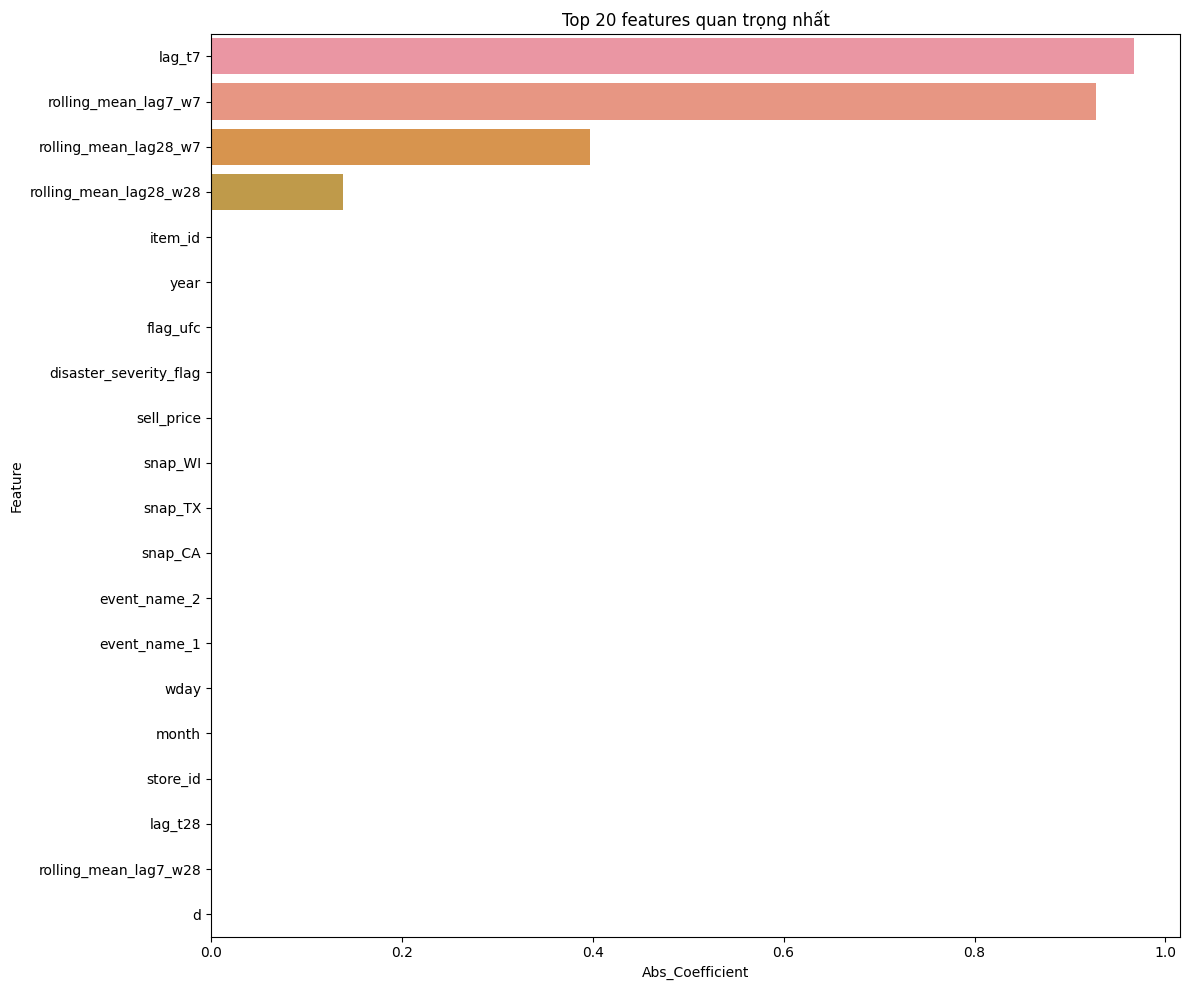


Số lượng feature quan trọng được lựa chọn: 4
Danh sách các feature quan trọng:
- lag_t7
- rolling_mean_lag7_w7
- rolling_mean_lag28_w7
- rolling_mean_lag28_w28


In [13]:
# Giả sử df là dataframe của bạn với các cột đã cho
# Chuẩn bị dữ liệu

df = df[:][:20000]
df = df.fillna(0)
X = df.drop(['demand','id'],axis=1)
y = df['demand']

# Chia dữ liệu thành tập train và test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Tìm alpha tối ưu bằng GridSearchCV
param_grid = {'alpha': np.logspace(-4, 2, 20)}
lasso_cv = GridSearchCV(Lasso(random_state=23520945, max_iter=10000), param_grid, cv=5, scoring='neg_mean_squared_error')
lasso_cv.fit(X_train_scaled, y_train)

# Lấy giá trị alpha tốt nhất
best_alpha = lasso_cv.best_params_['alpha']
print(f"Alpha tối ưu: {best_alpha}")

# Huấn luyện model với alpha tối ưu
lasso = Lasso(alpha=best_alpha, random_state=23520945, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

# Đánh giá mô hình
train_score = lasso.score(X_train_scaled, y_train)
test_score = lasso.score(X_test_scaled, y_test)
print(f"R² score trên tập train: {train_score:.4f}")
print(f"R² score trên tập test: {test_score:.4f}")

# Lấy các hệ số và tính mức độ quan trọng
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lasso.coef_
})

# Sắp xếp theo giá trị tuyệt đối của hệ số để xem mức độ quan trọng
feature_importance['Abs_Coefficient'] = abs(feature_importance['Coefficient'])
feature_importance = feature_importance.sort_values('Abs_Coefficient', ascending=False)

# In ra các feature có hệ số khác 0 (được chọn bởi Lasso)
selected_features = feature_importance[feature_importance['Coefficient'] != 0]
print("\nCác feature được chọn bởi Lasso:")
print(selected_features)

# Visualize feature importance
plt.figure(figsize=(12, 10))
sns.barplot(x='Abs_Coefficient', y='Feature', data=feature_importance.head(20))
plt.title('Top 20 features quan trọng nhất')
plt.tight_layout()
plt.show()

# Chỉ giữ lại các feature có ích nhất (hệ số khác 0)
important_features = feature_importance[feature_importance['Coefficient'] != 0]['Feature'].tolist()

print(f"\nSố lượng feature quan trọng được lựa chọn: {len(important_features)}")
print("Danh sách các feature quan trọng:")
for feature in important_features:
    print(f"- {feature}")

In [14]:
sample_submission = pd.read_csv('../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):
    
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x = prep_train(df, 1000 - 28)

del df
gc.collect()

['rolling_mean_lag28_w7', 'sell_price', 'state_id', 'disaster_severity_flag', 'snap_TX', 'gold_price', 'flag_ufc', 'month', 'wday', 'snap_WI', 'dept_id', 'lag_t28', 'snap_CA', 'store_id', 'lag_t7', 'item_id', 'rolling_mean_lag7_w7', 'event_name_1', 'year', 'rolling_mean_lag28_w28', 'event_name_2', 'cat_id', 'rolling_mean_lag7_w28']


6973

[LightGBM] [Info] Total Bins 2043
[LightGBM] [Info] Number of data points in the train set: 25053633, number of used features: 23
[LightGBM] [Info] Start training from score 0.206062
Training until validation scores don't improve for 200 rounds
[100]	valid_0's rmse: 2.64388
Did not meet early stopping. Best iteration is:
[100]	valid_0's rmse: 2.64388


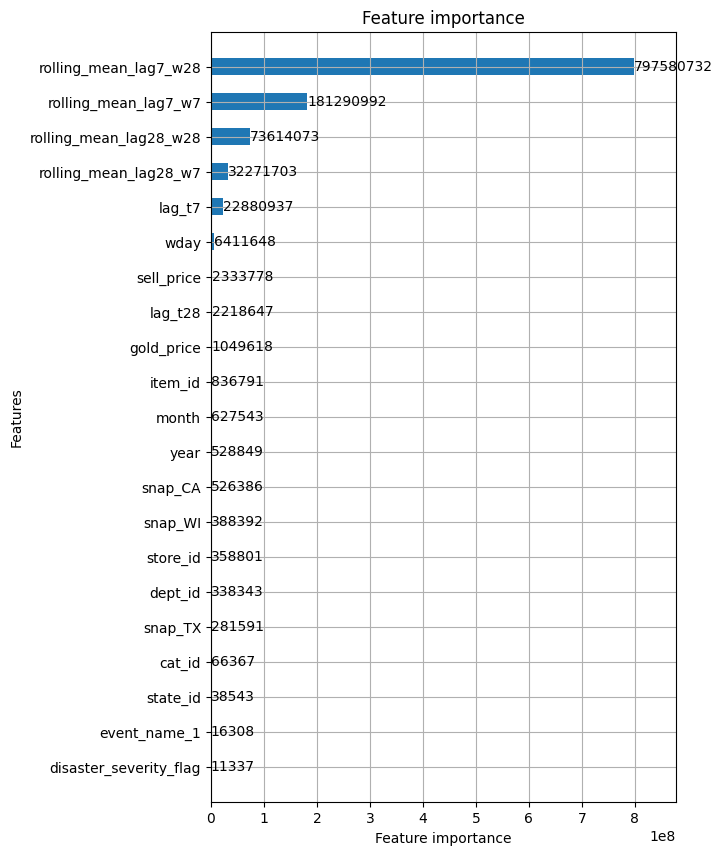

True

In [15]:
def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


fit = fit_model(train, valid,100)
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="submission.csv")